# CivicAI - 01 Data cleaning and EDA

This notebook has three parts:

1. **Target and threshold** (Phase 2) - build the thing we want to predict and check that the 7-day threshold is a sensible choice.
2. **Cleaning** (Phase 3) - find and fix problems in the raw data, and save the cleaned file.
3. **Exploratory charts** (Phase 3) - charts for the report.

# 1. Target and threshold

**Goal of this section.** The model will predict `resolved_within_7d`: 1 if a request was closed within 7 days of being created, otherwise 0. Before any modeling we check:

- how long requests really take to close,
- how balanced the two classes are at 7 days and at other possible thresholds,
- whether our 199,580-row sample looks like the full NYC 311 table.

**Rule we follow.** Everything about the threshold is measured on the *training period* only (the oldest 70% of requests). Looking at newer rows to pick the threshold would leak information from the validation and test data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_FILE = Path("../data/raw/nyc311_raw.parquet")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD_DAYS = 7                      # the project's target threshold
CANDIDATE_DAYS = [1, 2, 3, 5, 7, 14]    # thresholds we compare
TRAIN_SHARE = 0.70                      # oldest 70% = training period

# One simple chart style for the whole notebook
BLUE, GREY, INK = "#2a78d6", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
print("pandas", pd.__version__)

pandas 2.3.3


## 1.1 Load the raw data and parse the dates

The raw file keeps every column as text, exactly as the API sent it. Here we turn `created_date` and `closed_date` into real datetimes. `errors="coerce"` turns any text that is not a valid date into a missing value, so we can count parsing failures instead of crashing.

In [2]:
raw = pd.read_parquet(RAW_FILE)
print(f"Raw rows: {len(raw):,}   columns: {raw.shape[1]}")

df = raw[["unique_key", "created_date", "closed_date", "complaint_type", "borough"]].copy()
for col in ["created_date", "closed_date"]:
    parsed = pd.to_datetime(df[col], errors="coerce")
    # A parsing failure = the raw text was there, but it did not become a date
    failures = (df[col].notna() & parsed.isna()).sum()
    print(f"{col}: {df[col].isna().sum():,} missing in raw, {failures:,} parsing failures")
    df[col] = parsed

Raw rows: 199,580   columns: 44


created_date: 0 missing in raw, 0 parsing failures
closed_date: 702 missing in raw, 0 parsing failures


## 1.2 Duration, and rows we cannot use

`duration_hours` = `closed_date` minus `created_date`, in hours.

- **Missing `closed_date`**: no duration can be computed, so no target. Dropped.
- **Negative duration**: closed before it was created, which is impossible, so it is a data error. Dropped.
- **Zero duration**: closed at the exact second it was created. Strange, but it is a valid "resolved within 7 days", so we **keep** these and look at them again in Phase 3.

The rows are dropped only inside this notebook. The raw file on disk is not changed.

In [3]:
df["duration_hours"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600

n_missing = df["closed_date"].isna().sum()
n_negative = (df["duration_hours"] < 0).sum()
n_zero = (df["duration_hours"] == 0).sum()
print(f"Missing closed_date : {n_missing:,} ({n_missing / len(df):.2%})")
print(f"Negative duration   : {n_negative:,} ({n_negative / len(df):.2%})")
print(f"Zero duration       : {n_zero:,} ({n_zero / len(df):.2%})  (kept)")

work = df[df["duration_hours"].notna() & (df["duration_hours"] >= 0)].copy()
print(f"\nRows remaining after dropping missing and negative: {len(work):,} of {len(df):,}")

Missing closed_date : 702 (0.35%)


Negative duration   : 11 (0.01%)
Zero duration       : 3,458 (1.73%)  (kept)

Rows remaining after dropping missing and negative: 198,867 of 199,580


## 1.3 The training period

We sort by `created_date` and call the oldest 70% the training period. All threshold numbers below use only these rows.

(The final 70 / 15 / 15 split is made in Phase 4 on the cleaned data, so its cut-off date may move by a few hours. The idea is the same.)

In [4]:
work = work.sort_values("created_date").reset_index(drop=True)
n_train = int(len(work) * TRAIN_SHARE)
train = work.iloc[:n_train]
later = work.iloc[n_train:]
train_end = train["created_date"].max()

print(f"Training period : {len(train):,} rows, {train['created_date'].min()} to {train_end}")
print(f"Later rows      : {len(later):,} rows, {later['created_date'].min()} to {later['created_date'].max()}")

Training period : 139,206 rows, 2024-01-01 00:00:00 to 2025-12-02 20:45:49
Later rows      : 59,661 rows, 2025-12-02 20:48:18 to 2026-08-31 23:59:06


## 1.4 How long do requests take? (training period)

The table shows what share of training requests were closed within each candidate threshold. That share is the size of the positive class if we chose that threshold.

In [5]:
dur = train["duration_hours"]
shares = pd.DataFrame({
    "threshold_days": CANDIDATE_DAYS,
    "resolved_within": [(dur <= d * 24).mean() for d in CANDIDATE_DAYS],
})
shares["not_resolved_within"] = 1 - shares["resolved_within"]
shares["smaller_class"] = shares[["resolved_within", "not_resolved_within"]].min(axis=1)
display(shares.style.format({c: "{:.1%}" for c in shares.columns[1:]}).hide(axis="index"))

median_h, p75_h = dur.median(), dur.quantile(0.75)
print(f"Median duration         : {median_h:,.1f} hours = {median_h / 24:.2f} days")
print(f"75th percentile duration: {p75_h:,.1f} hours = {p75_h / 24:.2f} days")
print(f"Mean duration           : {dur.mean():,.1f} hours = {dur.mean() / 24:.2f} days")

threshold_days,resolved_within,not_resolved_within,smaller_class
1,61.6%,38.4%,38.4%
2,69.5%,30.5%,30.5%
3,74.6%,25.4%,25.4%
5,79.8%,20.2%,20.2%
7,82.8%,17.2%,17.2%
14,87.8%,12.2%,12.2%


Median duration         : 7.0 hours = 0.29 days


75th percentile duration: 74.0 hours = 3.08 days
Mean duration           : 286.6 hours = 11.94 days


**Histogram of duration.** Durations run from seconds to more than a year, so the x axis uses a log scale (each step is 10 times longer). Zero-duration rows cannot be drawn on a log axis, so they are left out of this chart only and counted in the title.

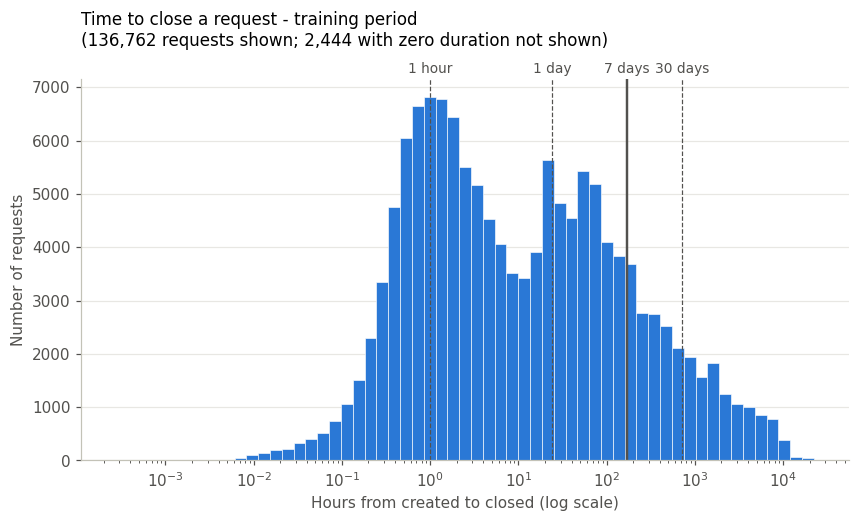

In [6]:
positive = dur[dur > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(positive, bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
for hours, label in [(1, "1 hour"), (24, "1 day"), (24 * 7, "7 days"), (24 * 30, "30 days")]:
    ax.axvline(hours, color=INK, linewidth=1.6 if hours == 168 else 0.8,
               linestyle="-" if hours == 168 else "--")
    ax.text(hours, 1.01, label, color=INK, fontsize=9, ha="center", va="bottom",
            transform=ax.get_xaxis_transform())   # label sits just above the plot
ax.set_xlabel("Hours from created to closed (log scale)")
ax.set_ylabel("Number of requests")
ax.set_title(f"Time to close a request - training period\n"
             f"({len(positive):,} requests shown; {(dur == 0).sum():,} with zero duration not shown)",
             loc="left", fontsize=11, pad=22)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "01_duration_histogram_log.png")
plt.show()

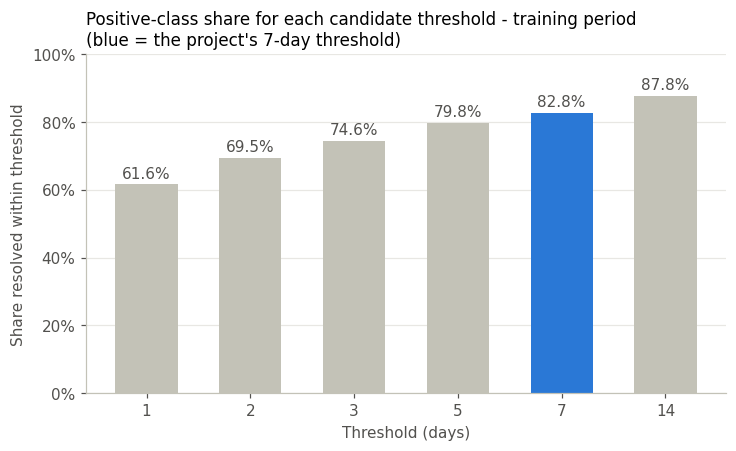

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
colors = [BLUE if d == THRESHOLD_DAYS else GREY for d in shares["threshold_days"]]
bars = ax.bar(shares["threshold_days"].astype(str), shares["resolved_within"], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in shares["resolved_within"]], color=INK, fontsize=10, padding=2)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Threshold (days)")
ax.set_ylabel("Share resolved within threshold")
ax.set_title("Positive-class share for each candidate threshold - training period\n(blue = the project's 7-day threshold)",
             loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "01_positive_share_by_threshold.png")
plt.show()

## 1.5 Class balance for the 7-day target

Class 1 = resolved within 7 days. Class 0 = took longer than 7 days.

In [8]:
work["resolved_within_7d"] = (work["duration_hours"] <= THRESHOLD_DAYS * 24).astype(int)
train = work.iloc[:n_train]

balance = train["resolved_within_7d"].value_counts().sort_index().rename("rows").to_frame()
balance["share"] = balance["rows"] / balance["rows"].sum()
balance.index = ["0 = took longer than 7 days", "1 = resolved within 7 days"]
display(balance.style.format({"rows": "{:,}", "share": "{:.1%}"}))

smaller = balance["share"].min()
print(f"Smaller class share: {smaller:.1%}  ->  {'UNDER' if smaller < 0.20 else 'above'} the 20% rule")

,rows,share
0 = took longer than 7 days,"23,929",17.2%
1 = resolved within 7 days,"115,277",82.8%


Smaller class share: 17.2%  ->  UNDER the 20% rule


**Does the target change over time?** This chart uses *all* months (not only the training period), only to see whether recent months look different. It is a check, not something we tune on.

One thing to keep in mind when reading it: our sample contains **closed** requests only. In the most recent months, slow requests that are still open are missing, which can push the recent share up a little.

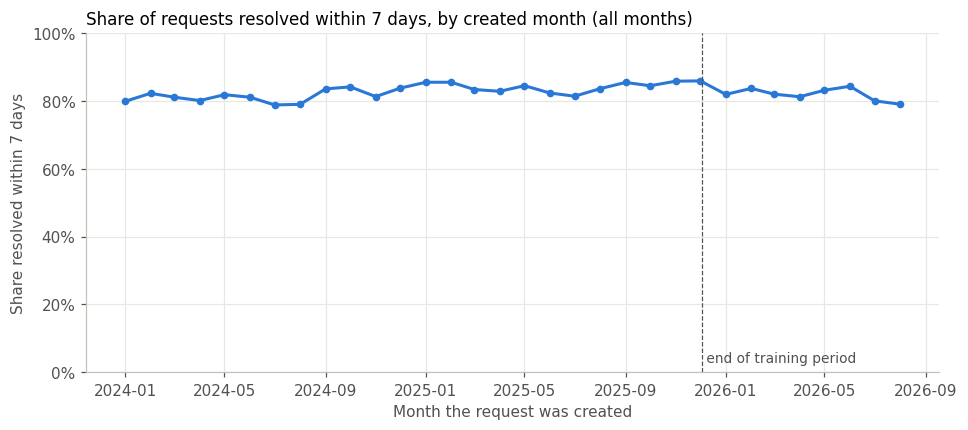

Training period : 82.8% resolved within 7 days
Later rows      : 82.4%
Lowest month    : 2024-07 at 78.9%
Highest month   : 2025-12 at 86.0%


In [9]:
by_month = work.groupby(work["created_date"].dt.to_period("M"))["resolved_within_7d"].agg(["mean", "size"])
by_month.index = by_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_month.index, by_month["mean"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.axvline(train_end, color=INK, linewidth=0.8, linestyle="--")
ax.text(train_end, 0.03, " end of training period", color=INK, fontsize=9)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Month the request was created")
ax.set_ylabel("Share resolved within 7 days")
ax.set_title("Share of requests resolved within 7 days, by created month (all months)", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "01_positive_share_by_month.png")
plt.show()

print(f"Training period : {train['resolved_within_7d'].mean():.1%} resolved within 7 days")
print(f"Later rows      : {work.iloc[n_train:]['resolved_within_7d'].mean():.1%}")
print(f"Lowest month    : {by_month['mean'].idxmin():%Y-%m} at {by_month['mean'].min():.1%}")
print(f"Highest month   : {by_month['mean'].idxmax():%Y-%m} at {by_month['mean'].max():.1%}")

## 1.6 Which complaint types are fast and which are slow?

Share resolved within 7 days for each complaint type, training period only, and only for types with at least 500 training rows (smaller types give noisy percentages). A big gap between the fastest and slowest types means `complaint_type` should be a strong feature.

In [10]:
by_type = train.groupby("complaint_type")["resolved_within_7d"].agg(rows="size", share_within_7d="mean")
big = by_type[by_type["rows"] >= 500].sort_values("share_within_7d", ascending=False)
print(f"Complaint types in training period: {len(by_type)}; with at least 500 rows: {len(big)} "
      f"(covering {big['rows'].sum() / len(train):.1%} of training rows)")

fmt = {"rows": "{:,}", "share_within_7d": "{:.1%}"}
print("\n10 types with the HIGHEST share resolved within 7 days")
display(big.head(10).style.format(fmt))
print("10 types with the LOWEST share resolved within 7 days")
display(big.tail(10).sort_values("share_within_7d").style.format(fmt))

Complaint types in training period: 172; with at least 500 rows: 50 (covering 92.0% of training rows)

10 types with the HIGHEST share resolved within 7 days


,rows,share_within_7d
complaint_type,,
Abandoned Vehicle,"2,802",100.0%
Drug Activity,996,100.0%
Noise - Commercial,"2,650",100.0%
Non-Emergency Police Matter,991,100.0%
Panhandling,502,100.0%
Vendor Enforcement,"1,112",100.0%
Noise - Vehicle,"1,852",100.0%
Noise - Street/Sidewalk,"6,901",100.0%
Illegal Parking,"21,763",100.0%


10 types with the LOWEST share resolved within 7 days


,rows,share_within_7d
complaint_type,,
Food Establishment,507,0.4%
For Hire Vehicle Complaint,798,1.3%
Noise - Helicopter,718,1.9%
Building/Use,798,15.5%
Maintenance or Facility,976,31.6%
GENERAL,"1,261",31.6%
Elevator,849,31.6%
APPLIANCE,901,32.7%
Overgrown Tree/Branches,656,37.3%


## 1.7 Is the sample representative of the full table?

We kept about 1 request in 48. To check the sample is fair, we ask the Socrata API to count **all** closed requests in the same date range, grouped by borough and by complaint type, and compare the shares with our sample. (All raw sample rows are used here, because the API counts include every closed request.)

The API answers are saved in `data/raw/` so the notebook can be re-run without calling the API again.

In [11]:
import io
sys.path.append("../src")
from fetch_data import BASE_URL, END, START, get   # same helper used for the data pull

def full_table_counts(column):
    """Count ALL closed requests in the date range, grouped by one column."""
    cache = Path(f"../data/raw/full_closed_by_{column}.csv")
    if not cache.exists():
        params = {
            "$select": f"{column}, count(*) as n",
            "$where": f"status = 'Closed' AND created_date >= '{START}T00:00:00' AND created_date < '{END}T00:00:00'",
            "$group": column,
            "$order": "n DESC",
            "$limit": 5000,
        }
        cache.write_text(get(BASE_URL + ".csv", params), encoding="utf-8", newline="")
    return pd.read_csv(cache, dtype={column: str}, keep_default_na=False).set_index(column)["n"]

def compare(column):
    full = full_table_counts(column)
    sample = raw[column].fillna("").value_counts()
    out = pd.DataFrame({"full_rows": full, "sample_rows": sample}).fillna(0)
    out["full_share"] = out["full_rows"] / out["full_rows"].sum()
    out["sample_share"] = out["sample_rows"] / out["sample_rows"].sum()
    out["diff_pct_points"] = (out["sample_share"] - out["full_share"]) * 100
    return out.sort_values("full_rows", ascending=False)

share_fmt = {"full_rows": "{:,.0f}", "sample_rows": "{:,.0f}", "full_share": "{:.2%}",
             "sample_share": "{:.2%}", "diff_pct_points": "{:+.2f}"}

boroughs = compare("borough")
print(f"Full table closed rows: {boroughs['full_rows'].sum():,.0f}   sample rows: {boroughs['sample_rows'].sum():,.0f}")
print("\nBorough shares: full table vs sample")
display(boroughs.style.format(share_fmt))

Full table closed rows: 9,581,154   sample rows: 199,580



Borough shares: full table vs sample


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
borough,,,,,
BROOKLYN,"2,894,302","60,050",30.21%,30.09%,-0.12
QUEENS,"2,310,448","48,164",24.11%,24.13%,+0.02
BRONX,"2,091,994","43,597",21.83%,21.84%,+0.01
MANHATTAN,"1,914,570","39,893",19.98%,19.99%,+0.01
STATEN ISLAND,"362,622","7,729",3.78%,3.87%,+0.09
Unspecified,"7,218",147,0.08%,0.07%,-0.00


In [12]:
types = compare("complaint_type")
print("Top 10 complaint types in the full table: full table vs sample")
display(types.head(10).style.format(share_fmt))

print("Largest differences across ALL complaint types (percentage points)")
largest = types.reindex(types["diff_pct_points"].abs().sort_values(ascending=False).index).head(5)
display(largest.style.format(share_fmt))

print(f"Largest borough difference       : {boroughs['diff_pct_points'].abs().max():.2f} percentage points")
print(f"Largest complaint-type difference: {types['diff_pct_points'].abs().max():.2f} percentage points")
print(f"Sample's top 10 types are the same as the full table's top 10: "
      f"{set(types.head(10).index) == set(types.sort_values('sample_rows', ascending=False).head(10).index)}")

Top 10 complaint types in the full table: full table vs sample


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
complaint_type,,,,,
Illegal Parking,"1,498,254","31,272",15.64%,15.67%,+0.03
Noise - Residential,"1,092,670","22,790",11.40%,11.42%,+0.01
HEAT/HOT WATER,"774,994","16,139",8.09%,8.09%,-0.00
Blocked Driveway,"473,318","9,922",4.94%,4.97%,+0.03
Noise - Street/Sidewalk,"460,904","9,547",4.81%,4.78%,-0.03
UNSANITARY CONDITION,"327,318","6,787",3.42%,3.40%,-0.02
Street Condition,"227,347","4,743",2.37%,2.38%,+0.00
Water System,"196,873","4,107",2.05%,2.06%,+0.00
PLUMBING,"191,979","4,029",2.00%,2.02%,+0.02


Largest differences across ALL complaint types (percentage points)


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
complaint_type,,,,,
ELECTRIC,"82,430","1,624",0.86%,0.81%,-0.05
Dirty Condition,"166,381","3,393",1.74%,1.70%,-0.04
Graffiti,"52,707","1,169",0.55%,0.59%,+0.04
Drug Activity,"57,692","1,139",0.60%,0.57%,-0.03
Illegal Parking,"1,498,254","31,272",15.64%,15.67%,+0.03


Largest borough difference       : 0.12 percentage points
Largest complaint-type difference: 0.05 percentage points
Sample's top 10 types are the same as the full table's top 10: True


## 1.8 Threshold recommendation

**What the numbers say (training period, 139,206 rows, 2024-01-01 to 2025-12-02):**

- With the 7-day threshold, **82.8%** of requests are class 1 (resolved within 7 days) and **17.2%** are class 0.
- The smaller class is **under the project's 20% guide**, by 2.8 percentage points. By the project rules this must be raised with the student, so the threshold is **not changed here**.
- Durations are very uneven: the median is only 7.0 hours, the 75th percentile is 3.08 days, but the mean is 11.9 days because a small number of requests stay open for months.
- The 7-day share is stable over time: every month is between 78.9% and 86.0%, and the later rows (82.4%) look like the training period (82.8%). So one threshold works for the whole date range.
- The sample matches the full table of 9,581,154 closed requests closely: the largest borough difference is 0.12 percentage points and the largest complaint-type difference is 0.05.

**Options:**

| Threshold | Class 1 | Class 0 (smaller) | Comment |
| --- | --- | --- | --- |
| 7 days (current) | 82.8% | 17.2% | Easy to explain ("within a week"); slightly under the 20% guide |
| 5 days | 79.8% | 20.2% | Closest threshold that passes the guide, but only just, and "5 days" is a less natural cut-off |
| 3 days | 74.6% | 25.4% | Clearly better balance; still easy to explain |
| Median (7.0 hours) | 50% | 50% | Perfect balance, but it changes the question to "is it closed the same day?" |

**Recommendation: keep 7 days.** The imbalance is mild (about 1 in 6 rows is the smaller class, which is 23,929 training rows, plenty to learn from). It can be handled without changing the question, by using `class_weight="balanced"` in the models and judging them with macro F1 and ROC-AUC instead of accuracy alone. A majority-class baseline would score 82.8% accuracy, so accuracy alone must not be used to claim success.

**If a better balance is preferred, the proposed alternative is 3 days** (25.4% in the smaller class). 5 days is the closest value that passes the 20% guide, but it passes by only 0.2 points.

**One more thing to know.** Complaint type almost decides the answer on its own: several large types (for example Illegal Parking and the noise types) are resolved within 7 days essentially 100% of the time, and a few (Food Establishment, For Hire Vehicle Complaint, Noise - Helicopter) almost never are. The models should score well, and most of the skill will come from `complaint_type`. This is true at any of the thresholds above.

**Decision (confirmed by the student):** keep the 7-day threshold. `resolved_within_7d` = 1 if the duration is 7 days or less, else 0.

# 2. Cleaning

**How this section works.** Each problem gets the same four parts: a **check** (how big is the problem?), a **chart**, the **fix**, and the **reason** for the decision.

The fixes themselves are functions in `src/preprocessing.py`. The notebook calls those functions, so the API can later clean an incoming request with exactly the same code.

**Two rules we follow:**

- Anything *learned from the data* (which columns are almost empty, which categories are too rare to keep) is learned from the **training period only** - the oldest 70% of requests. The newer 30% is kept for validation and testing, so it must not influence any decision.
- Columns that are only known *after* a request is filed (`closed_date`, `status`, `resolution_description`, ...) are never model inputs. `closed_date` is used once to build the target and is then dropped.

**Order.** Types and text are fixed first, because values such as `"Unspecified"` and `"N/A"` are really missing values and should be counted as missing.

In [13]:
import json
import preprocessing as pp     # src/preprocessing.py (the folder was added to the path in 1.7)

ORANGE = "#eb6834"             # used to mark "problem" or "dropped" in charts
cleaning_log = []              # one row per issue; saved as reports/cleaning_log.csv at the end

def log(issue, check, rows_affected, action):
    cleaning_log.append({"issue": issue, "check": check,
                         "rows_affected": int(rows_affected), "action": action})

# Training period of the raw rows (used for every decision that is learned from data)
usable = pp.drop_unusable_rows(pp.add_target(pp.convert_dates(raw)))
usable = usable.sort_values(["created_date", "unique_key"]).reset_index(drop=True)
raw_train = pp.training_period(usable)
print(f"Raw rows: {len(raw):,}")
print(f"Rows with a valid target: {len(usable):,}")
print(f"Training period: {len(raw_train):,} rows, {raw_train['created_date'].min()} to {raw_train['created_date'].max()}")

Raw rows: 199,580
Rows with a valid target: 198,867
Training period: 139,206 rows, 2024-01-01 00:00:00 to 2025-12-02 20:45:49


## 2.1 Wrong types

**Check.** The raw file stores all 44 columns as text. Five of the columns we need are not really text: two dates, two numbers and a ZIP code. For each one we count how many values are valid, missing, or present but invalid.

A ZIP code counts as valid only if it has exactly 5 digits **and** starts with an NYC prefix (100-104, 110-114, 116). `10000` has an NYC prefix but is not a real ZIP code, so it is invalid too.

In [14]:
print("Column types in the raw file:", raw.dtypes.astype(str).value_counts().to_dict())

def validity(name, raw_col, converted):
    missing = raw_col.isna().sum()
    invalid = (raw_col.notna() & converted.isna()).sum()
    return {"column": name, "valid": len(raw_col) - missing - invalid, "missing": missing, "invalid": invalid}

dates = pp.convert_dates(raw)
coords = pp.clean_coordinates(raw)
types = pd.DataFrame([
    validity("created_date", raw["created_date"], dates["created_date"]),
    validity("closed_date", raw["closed_date"], dates["closed_date"]),
    validity("latitude", raw["latitude"], coords["latitude"]),
    validity("longitude", raw["longitude"], coords["longitude"]),
    validity("incident_zip", raw["incident_zip"], pp.clean_zip(raw["incident_zip"])),
]).set_index("column")
types["new_type"] = ["datetime", "datetime", "number", "number", "5-digit text"]
display(types.style.format({c: "{:,}" for c in ["valid", "missing", "invalid"]}))

bad_zip = raw["incident_zip"][raw["incident_zip"].notna() & pp.clean_zip(raw["incident_zip"]).isna()]
print("Invalid ZIP values and how often they appear:", bad_zip.value_counts().to_dict())

Column types in the raw file: {'object': 44}


,valid,missing,invalid,new_type
column,,,,
created_date,"199,580",0,0,datetime
closed_date,"198,878",702,0,datetime
latitude,"196,284","3,296",0,number
longitude,"196,284","3,296",0,number
incident_zip,"197,701","1,843",36,5-digit text


Invalid ZIP values and how often they appear: {'10000': 29, '92879': 1, '12345': 1, '11550': 1, '11776': 1, '3723': 1, '10803': 1, '10604': 1}


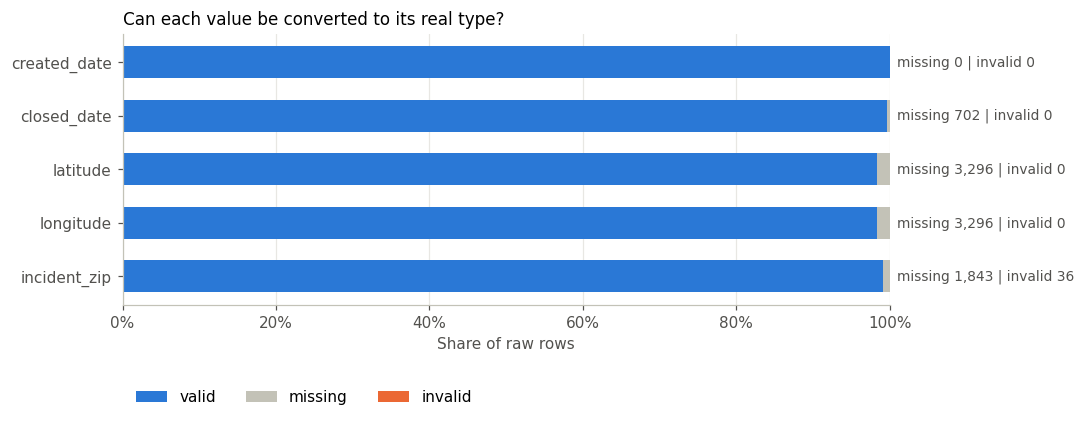

In [15]:
share = types[["valid", "missing", "invalid"]].div(len(raw)) * 100
fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(share))
for part, color in [("valid", BLUE), ("missing", GREY), ("invalid", ORANGE)]:
    ax.barh(share.index, share[part], left=left, color=color, label=part, height=0.6)
    left += share[part].values
for i, (name, row) in enumerate(types.iterrows()):
    ax.text(101, i, f"missing {row['missing']:,} | invalid {row['invalid']:,}", va="center", color=INK, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Share of raw rows")
ax.set_title("Can each value be converted to its real type?", loc="left", fontsize=11)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, -0.42), frameon=False)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_type_conversion.png")
plt.show()

**Fix** (`pp.convert_dates`, `pp.clean_coordinates`, `pp.clean_zip`):

- `created_date` and `closed_date` become datetimes. Every non-empty value parsed, so nothing was lost.
- `latitude` and `longitude` become numbers. Every non-empty value was a valid number.
- `incident_zip` stays **text** with 5 digits. A ZIP code is a label, not a quantity (ZIP 11201 is not "more" than 10001), and text keeps any leading zero. The few invalid ZIP values are treated as missing rather than guessed.

In [16]:
log("Wrong types", "created_date / closed_date stored as text; values that fail to parse",
    types.loc[["created_date", "closed_date"], "invalid"].sum(), "Converted to datetime; no parsing failures")
log("Wrong types", "latitude / longitude stored as text; values that are not numbers",
    types.loc[["latitude", "longitude"], "invalid"].sum(), "Converted to numbers; no failures")
log("Wrong types", "incident_zip not 5 digits or not an NYC ZIP code",
    types.loc["incident_zip", "invalid"], "Kept as 5-digit text; invalid values set to 'Unknown'")

## 2.2 Inconsistent data

**Check.** For each text column we keep, we look for three kinds of inconsistency:

1. **Case and spacing** - the same value written two ways, such as `ELEVATOR` and `Elevator`, or with double spaces.
2. **Placeholder values** - text such as `Unspecified`, `N/A` or `UNKNOWN` that really means "no value".
3. **Invalid ZIP codes** - counted in 2.1.

In [17]:
rows = []
for col in pp.CATEGORICAL_COLUMNS:
    before = raw[col]
    spaced = before.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    after = pp.clean_features(raw[[col]])[col]
    placeholder = before.notna() & (after == pp.UNKNOWN)
    if col == "incident_zip":
        placeholder &= False                       # invalid ZIPs are counted in 2.1, not here
    rows.append({
        "column": col,
        "unique_before": before.nunique(),
        "unique_after": after[after != pp.UNKNOWN].nunique(),
        "rows_with_extra_spaces": int((before.notna() & (before != spaced)).sum()),
        "values_merged_by_case": before.nunique() - spaced.str.upper().nunique(),
        "placeholder_rows": int(placeholder.sum()),
    })
inconsistent = pd.DataFrame(rows).set_index("column")
display(inconsistent.style.format("{:,}"))

# Examples of the same value written in two ways
for col in ["complaint_type", "descriptor", "location_type"]:
    values = raw[col].dropna()
    groups = values.groupby(values.str.upper().str.replace(r"\s+", " ", regex=True)).unique()
    print(f"{col}: written more than one way ->", [list(g) for g in groups if len(g) > 1])

,unique_before,unique_after,rows_with_extra_spaces,values_merged_by_case,placeholder_rows
column,,,,,
agency,16,16,0,0,0
complaint_type,181,179,0,2,0
descriptor,829,825,52,3,"4,176"
location_type,123,120,0,1,81
incident_zip,233,225,0,0,0
address_type,6,6,0,0,0
community_board,77,71,0,0,"2,617"
borough,6,5,0,0,147
open_data_channel_type,5,4,0,0,"15,276"


complaint_type: written more than one way -> [['Elevator', 'ELEVATOR'], ['PLUMBING', 'Plumbing']]


descriptor: written more than one way -> [['DOOR', 'Door'], ['LIGHTING', 'Lighting'], ['SEWAGE', 'Sewage']]


location_type: written more than one way -> [['RESIDENTIAL BUILDING', 'Residential Building']]


In [18]:
print("open_data_channel_type before and after:")
display(pd.DataFrame({"before": raw["open_data_channel_type"].value_counts(),
                      "after": pp.clean_features(raw[["open_data_channel_type"]])["open_data_channel_type"].value_counts()})
        .fillna(0).astype(int).sort_values("before", ascending=False).style.format("{:,}"))

print("Placeholder values found in the kept columns:")
for col in ["borough", "open_data_channel_type", "descriptor", "location_type", "community_board"]:
    after = pp.clean_features(raw[[col]])[col]
    found = raw[col][raw[col].notna() & (after == pp.UNKNOWN)].value_counts()
    print(f"  {col}: {found.to_dict()}")

open_data_channel_type before and after:


,before,after
open_data_channel_type,,
ONLINE,"86,182","86,182"
PHONE,"54,329","54,329"
MOBILE,"43,755","43,755"
UNKNOWN,"15,276",0
OTHER,38,0
Other,0,38
Unknown,0,"15,276"


Placeholder values found in the kept columns:


  borough: {'Unspecified': 147}


  open_data_channel_type: {'UNKNOWN': 15276}


  descriptor: {'N/A': 4176}


  location_type: {'N/A': 76, 'Unknown': 5}


  community_board: {'Unspecified MANHATTAN': 767, 'Unspecified QUEENS': 634, 'Unspecified BROOKLYN': 603, 'Unspecified BRONX': 378, '0 Unspecified': 147, 'Unspecified STATEN ISLAND': 88}


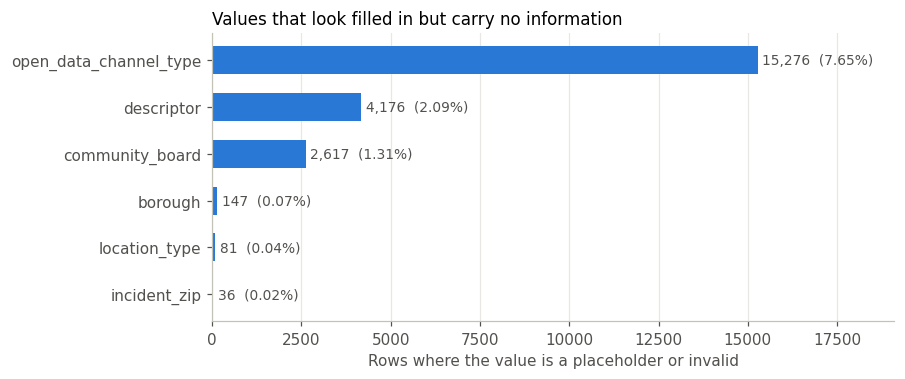

In [19]:
plot = inconsistent["placeholder_rows"].copy()
plot["incident_zip"] = types.loc["incident_zip", "invalid"]     # invalid ZIPs, from 2.1
plot = plot[plot > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}  ({v / len(raw):.2%})" for v in plot.values], color=INK, fontsize=9, padding=3)
ax.set_xlim(0, plot.max() * 1.25)
ax.set_xlabel("Rows where the value is a placeholder or invalid")
ax.set_title("Values that look filled in but carry no information", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_placeholder_values.png")
plt.show()

**Fix** (`pp.standardize_text` inside `pp.clean_features`):

- **Trim spaces, collapse double spaces and upper-case** every kept text column. Upper-case is used because the borough and many complaint types are already upper-case, and because the API can then accept `"brooklyn"`, `"Brooklyn"` or `"BROOKLYN"` as the same value.
- **Placeholders become `"Unknown"`**: `Unspecified`, `N/A`, `UNKNOWN`, and community boards such as `Unspecified BROOKLYN` that name no real board. One label for "no value" is clearer than five.
- `open_data_channel_type` has only five values and no spelling problems. `UNKNOWN` (7.7% of rows) becomes `Unknown`; the others are kept.

**One side effect to know about.** `ELEVATOR` (HPD) and `Elevator` (Department of Buildings) become one complaint type, and the same for `PLUMBING` / `Plumbing`. They come from different agencies. We accept this because the `agency` column is kept, so the difference is not lost.

In [20]:
log("Inconsistent data", "Text with different case or extra spaces in kept text columns",
    inconsistent["rows_with_extra_spaces"].sum(),
    f"Trimmed, single-spaced and upper-cased; {inconsistent['values_merged_by_case'].sum()} duplicate spellings merged")
for col in ["borough", "open_data_channel_type", "descriptor", "location_type", "community_board"]:
    log("Inconsistent data", f"Placeholder values in {col} (Unspecified, N/A, UNKNOWN)",
        inconsistent.loc[col, "placeholder_rows"], "Mapped to 'Unknown'")

## 2.3 Missing values

**Check.** Percent missing for all 44 raw columns. `null_pct` is truly empty cells. `placeholder_pct` is cells that hold placeholder text (`Unspecified`, `N/A`, ...). `missing_pct` is the two together, which is the honest measure. The last column repeats `missing_pct` for the training period only, because the decision to drop a column is made on training rows.

In [21]:
missing_all = pp.missing_table(raw)
missing_train = pp.missing_table(raw_train[raw.columns])
missing = missing_all.assign(train_missing_pct=missing_train["missing_pct"])
display(missing.style.format("{:.2f}%"))

,null_pct,placeholder_pct,missing_pct,train_missing_pct
column,,,,
taxi_company_borough,99.95%,0.00%,99.95%,99.94%
road_ramp,99.73%,0.00%,99.73%,99.77%
bridge_highway_direction,99.69%,0.00%,99.69%,99.75%
facility_type,92.54%,7.12%,99.66%,99.63%
park_facility_name,0.00%,99.63%,99.63%,99.49%
due_date,99.49%,0.00%,99.49%,99.44%
bridge_highway_segment,99.42%,0.00%,99.42%,99.55%
bridge_highway_name,99.42%,0.00%,99.42%,99.55%
taxi_pick_up_location,99.20%,0.00%,99.20%,99.02%


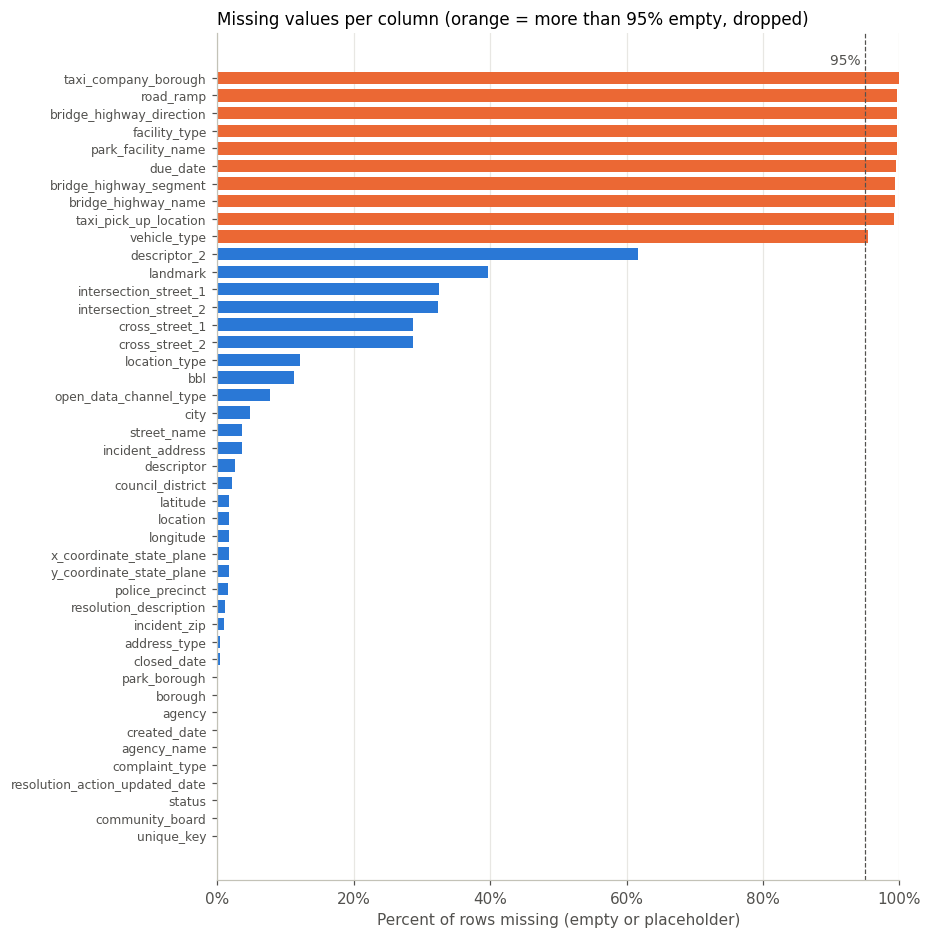

Columns more than 95% empty in the training period (10), dropped:


,missing_pct,train_missing_pct
column,,
taxi_company_borough,99.95%,99.94%
road_ramp,99.73%,99.77%
bridge_highway_direction,99.69%,99.75%
facility_type,99.66%,99.63%
park_facility_name,99.63%,99.49%
due_date,99.49%,99.44%
bridge_highway_segment,99.42%,99.55%
bridge_highway_name,99.42%,99.55%
taxi_pick_up_location,99.20%,99.02%


In [22]:
too_empty = missing.index[missing["train_missing_pct"] > pp.MAX_MISSING_SHARE * 100].tolist()

plot = missing["missing_pct"].sort_values()
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(plot.index, plot.values, color=[ORANGE if c in too_empty else BLUE for c in plot.index], height=0.7)
ax.axvline(95, color=INK, linewidth=0.8, linestyle="--")
ax.text(95, len(plot) - 0.4, "95% ", color=INK, fontsize=9, ha="right", va="bottom")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Percent of rows missing (empty or placeholder)")
ax.set_title("Missing values per column (orange = more than 95% empty, dropped)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
fig.savefig(FIG_DIR / "02_missing_by_column.png")
plt.show()

print(f"Columns more than 95% empty in the training period ({len(too_empty)}), dropped:")
display(missing.loc[too_empty, ["missing_pct", "train_missing_pct"]].style.format("{:.2f}%"))

**Fix, part 1 - drop columns that are more than 95% empty.** A column that is empty for more than 19 rows in 20 cannot help a general model. Most of these only apply to one kind of request (taxi and bridge/highway complaints). `park_facility_name` and `facility_type` look filled in but hold `Unspecified` or `N/A` almost everywhere.

**Fix, part 2 - one rule for every remaining column.** There are three possible rules:

- **Fill with "Unknown"** - for text columns we keep. "The caller did not give this" is itself useful information, and a label keeps the row.
- **Leave missing** - for the numbers `latitude` and `longitude`. There is no honest value to put in. Tree models can use missing numbers directly; for Logistic Regression the pipeline in Phase 4 will fill them with a value learned from the training rows.
- **Drop the column** - if it leaks the answer, duplicates another column, or is a free-text address with thousands of different values.

In [23]:
FILL, LEAVE, DROP, KEEP = "Fill with 'Unknown'", "Leave missing", "Drop column", "Keep (nothing missing)"
ADDRESS = "Free-text street address with thousands of different values; location is already covered by ZIP, borough and coordinates"
rules = {
    "unique_key": (KEEP, "Request id. Kept to identify rows, never used as a feature"),
    "created_date": (KEEP, "When the request was filed; source of hour, weekday and month"),
    "closed_date": (DROP, "Leakage: only known after the request is resolved. Used once for the target; the 702 rows without it are dropped"),
    "status": (DROP, "Leakage, and it has one value only (Closed)"),
    "resolution_description": (DROP, "Leakage: written when the request is resolved"),
    "resolution_action_updated_date": (DROP, "Leakage: a later update timestamp"),
    "agency": (KEEP, "Agency the request is routed to; Phase 4 decides if it is known at filing"),
    "agency_name": (DROP, "Same information as agency, written out in full"),
    "complaint_type": (KEEP, "Main candidate feature"),
    "descriptor": (FILL, "Candidate feature; a missing detail is information"),
    "descriptor_2": (DROP, "Missing for more than 60% of rows, and only a finer detail of descriptor"),
    "location_type": (FILL, "Candidate feature; missing mostly for agencies that do not record it, so 'Unknown' is informative"),
    "incident_zip": (FILL, "Candidate feature; missing or invalid ZIP becomes 'Unknown'"),
    "address_type": (FILL, "Kept for Phase 4 to judge; few missing"),
    "community_board": (FILL, "Kept for Phase 4 to judge; 'Unspecified ...' boards become 'Unknown'"),
    "borough": (FILL, "Candidate feature; 147 'Unspecified' rows become 'Unknown'"),
    "open_data_channel_type": (FILL, "Candidate feature; 'UNKNOWN' becomes 'Unknown'"),
    "latitude": (LEAVE, "Number with no honest fill value; handled inside the model pipeline"),
    "longitude": (LEAVE, "Number with no honest fill value; handled inside the model pipeline"),
    "incident_address": (DROP, ADDRESS), "street_name": (DROP, ADDRESS),
    "cross_street_1": (DROP, ADDRESS), "cross_street_2": (DROP, ADDRESS),
    "intersection_street_1": (DROP, ADDRESS), "intersection_street_2": (DROP, ADDRESS),
    "landmark": (DROP, ADDRESS),
    "city": (DROP, "Repeats borough and ZIP (for example BROOKLYN, or a Queens neighbourhood name)"),
    "council_district": (DROP, "Another area code; community_board and ZIP already describe the area"),
    "police_precinct": (DROP, "Another area code; community_board and ZIP already describe the area"),
    "bbl": (DROP, "Building id with tens of thousands of values; missing for 11% of rows"),
    "x_coordinate_state_plane": (DROP, "Same location as longitude in another unit"),
    "y_coordinate_state_plane": (DROP, "Same location as latitude in another unit"),
    "location": (DROP, "Text copy of latitude and longitude"),
    "park_borough": (DROP, f"Identical to borough in every row: {(raw['park_borough'] == raw['borough']).all()}"),
}
remaining = [c for c in raw.columns if c not in too_empty]
assert set(rules) == set(remaining), set(rules) ^ set(remaining)     # every remaining column has a rule

rule_table = pd.DataFrame(rules, index=["rule", "reason"]).T.loc[remaining]
rule_table.insert(0, "missing_pct", missing["missing_pct"])
with pd.option_context("display.max_colwidth", None):
    display(rule_table.style.format({"missing_pct": "{:.2f}%"}).set_properties(**{"text-align": "left"}))

kept_columns = [c for c in remaining if rules[c][0] != DROP]
assert set(kept_columns) | {"duration_hours", "resolved_within_7d"} == set(pp.CLEAN_COLUMNS)
print(f"Rule counts: {rule_table['rule'].value_counts().to_dict()}")

,missing_pct,rule,reason
unique_key,0.00%,Keep (nothing missing),"Request id. Kept to identify rows, never used as a feature"
created_date,0.00%,Keep (nothing missing),"When the request was filed; source of hour, weekday and month"
closed_date,0.35%,Drop column,Leakage: only known after the request is resolved. Used once for the target; the 702 rows without it are dropped
agency,0.00%,Keep (nothing missing),Agency the request is routed to; Phase 4 decides if it is known at filing
agency_name,0.00%,Drop column,"Same information as agency, written out in full"
complaint_type,0.00%,Keep (nothing missing),Main candidate feature
descriptor,2.58%,Fill with 'Unknown',Candidate feature; a missing detail is information
descriptor_2,61.75%,Drop column,"Missing for more than 60% of rows, and only a finer detail of descriptor"
location_type,12.07%,Fill with 'Unknown',"Candidate feature; missing mostly for agencies that do not record it, so 'Unknown' is informative"
incident_zip,0.92%,Fill with 'Unknown',Candidate feature; missing or invalid ZIP becomes 'Unknown'


Rule counts: {'Drop column': 21, "Fill with 'Unknown'": 7, 'Keep (nothing missing)': 4, 'Leave missing': 2}


In [24]:
log("Missing values", "Columns more than 95% empty (null or placeholder) in the training period",
    0, f"No rows removed. Dropped {len(too_empty)} columns: {', '.join(too_empty)}")
n_drop = sum(rule == DROP for rule, _ in rules.values())
log("Missing values", "Remaining columns that leak the answer, repeat another column or are free-text addresses",
    0, f"No rows removed. Dropped {n_drop} more columns (see the rule table in notebook 2.3)")
for col in ["descriptor", "location_type", "incident_zip", "address_type", "community_board", "borough", "open_data_channel_type"]:
    log("Missing values", f"{col} empty, placeholder or invalid (includes the placeholder rows listed above)",
        round(missing.loc[col, 'missing_pct'] / 100 * len(raw)) if col != "community_board"
        else (pp.clean_features(raw[[col]])[col] == pp.UNKNOWN).sum(),
        "Filled with 'Unknown'")
log("Missing values", "latitude / longitude empty", raw["latitude"].isna().sum(),
    "Left missing (NaN); the model pipeline handles it in Phase 4")

## 2.4 Duplicates

**Check.** Three levels:

1. the same `unique_key` twice (the same request downloaded twice),
2. two rows identical in all 44 columns,
3. **near-duplicates**: different `unique_key`, but the same complaint type, the same place and the same `created_date` to the second. Place is checked two ways: by address and by coordinates.

In [25]:
by_address = ["complaint_type", "incident_address", "created_date"]
by_coords = ["complaint_type", "latitude", "longitude", "created_date"]
has_address = raw.dropna(subset=by_address)
has_coords = raw.dropna(subset=by_coords)

duplicates = pd.Series({
    "Same unique_key": raw["unique_key"].duplicated().sum(),
    "Identical in all columns": raw.duplicated().sum(),
    "Near-duplicate (type + address + time)": has_address.duplicated(by_address).sum(),
    "Near-duplicate (type + coordinates + time)": has_coords.duplicated(by_coords).sum(),
}, name="extra_rows")
display(duplicates.to_frame().style.format("{:,}"))

near = has_address[has_address.duplicated(by_address, keep=False)]
print(f"Rows that belong to a near-duplicate group (by address): {len(near):,} ({len(near) / len(raw):.2%} of rows)")
print("By agency:", near["agency"].value_counts().to_dict())
print("Rows in these groups that also share the same descriptor:",
      int(near.duplicated(by_address + ["descriptor"], keep=False).sum()))
print("\nExample near-duplicate groups:")
display(near.sort_values(by_address).head(6)[["unique_key", "created_date", "agency", "complaint_type", "descriptor", "incident_address"]])

,extra_rows
Same unique_key,0
Identical in all columns,0
Near-duplicate (type + address + time),119
Near-duplicate (type + coordinates + time),118


Rows that belong to a near-duplicate group (by address): 238 (0.12% of rows)
By agency: {'HPD': 200, 'NYPD': 13, 'DHS': 11, 'DEP': 8, 'DOT': 4, 'DSNY': 2}
Rows in these groups that also share the same descriptor: 116

Example near-duplicate groups:


,unique_key,created_date,agency,complaint_type,descriptor,incident_address
67865,63419472,2024-12-16T22:34:59.000,HPD,APPLIANCE,ELECTRIC/GAS RANGE,245 WADSWORTH AVENUE
67940,63423216,2024-12-16T22:34:59.000,HPD,APPLIANCE,ELECTRIC/GAS RANGE,245 WADSWORTH AVENUE
78191,63942528,2025-01-31T15:59:38.000,HPD,APPLIANCE,REFRIGERATOR,27 ELY STREET
78239,63945408,2025-01-31T15:59:38.000,HPD,APPLIANCE,ELECTRIC/GAS RANGE,27 ELY STREET
73654,63710976,2025-01-10T11:05:00.000,DEP,Air Quality,"Air: Odor/Fumes, Vehicle Idling (AD3)",640 8 AVENUE
73777,63717072,2025-01-10T11:05:00.000,DEP,Air Quality,"Air: Odor/Fumes, Vehicle Idling (AD3)",640 8 AVENUE


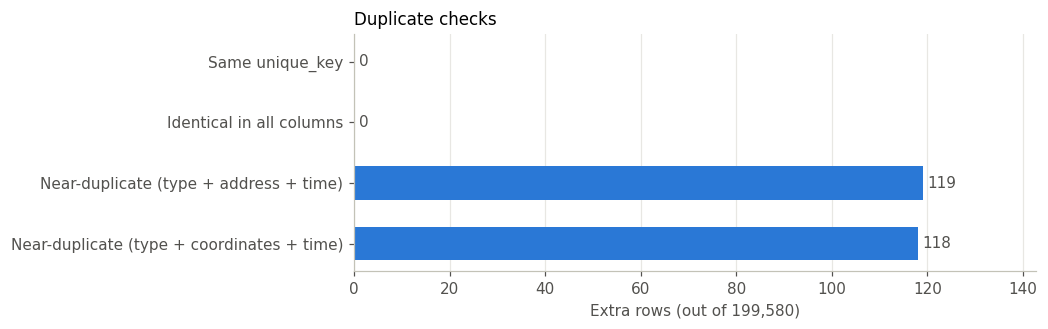

In [26]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(duplicates.index, duplicates.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:,}" for v in duplicates.values], color=INK, fontsize=10, padding=3)
ax.invert_yaxis()
ax.set_xlim(0, max(duplicates.max() * 1.2, 10))
ax.set_xlabel(f"Extra rows (out of {len(raw):,})")
ax.set_title("Duplicate checks", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_duplicates.png")
plt.show()

**Fix.** Remove exact duplicates only (`drop_duplicates` on all columns, then on `unique_key`). There are none, so no rows are removed. This was expected: the sample was taken by `unique_key`, so each request can appear only once.

**Near-duplicates are kept.** Each one has its own `unique_key`, so the city recorded it as a separate request. Several people can report the same noisy party, and one caller can report several problems in one flat at the same moment. They are about 0.1% of rows, so they cannot change the results, and deleting real requests would be a bigger mistake than keeping them.

In [27]:
log("Duplicates", "Same unique_key more than once", duplicates["Same unique_key"], "Exact duplicates removed (none found)")
log("Duplicates", "Rows identical in all 44 columns", duplicates["Identical in all columns"], "Exact duplicates removed (none found)")
log("Duplicates", "Near-duplicates: same complaint type, address and created_date, different unique_key",
    duplicates["Near-duplicate (type + address + time)"], "Kept: each is a separate request with its own id")

## 2.5 Outliers

Four things are checked: very long durations, zero and negative durations, coordinates outside New York City, and unusual `created_date` values.

### Extreme durations

**Check.** `usable` holds every row with a valid (non-negative) duration.

In [28]:
d = usable["duration_hours"]
quantiles = d.quantile([0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1.0]).rename("hours").to_frame()
quantiles["days"] = quantiles["hours"] / 24
quantiles.index = ["25%", "median", "75%", "90%", "99%", "99.9%", "longest"]
display(quantiles.style.format("{:,.1f}"))

iqr = d.quantile(0.75) - d.quantile(0.25)
upper_fence = d.quantile(0.75) + 1.5 * iqr
print(f"Boxplot rule (75th percentile + 1.5 x IQR): durations above {upper_fence:,.0f} hours "
      f"({upper_fence / 24:.1f} days) count as outliers -> {(d > upper_fence).sum():,} rows ({(d > upper_fence).mean():.1%})")
print(f"Longer than 30 days : {(d > 30 * 24).sum():,} ({(d > 30 * 24).mean():.1%})")
print(f"Longer than 365 days: {(d > 365 * 24).sum():,} ({(d > 365 * 24).mean():.2%})")

,hours,days
25%,1.1,0.0
median,7.4,0.3
75%,76.6,3.2
90%,469.3,19.6
99%,"5,113.1",213.0
99.9%,"10,554.6",439.8
longest,"22,245.2",926.9


Boxplot rule (75th percentile + 1.5 x IQR): durations above 190 hours (7.9 days) count as outliers -> 32,221 rows (16.2%)
Longer than 30 days : 15,237 (7.7%)
Longer than 365 days: 511 (0.26%)


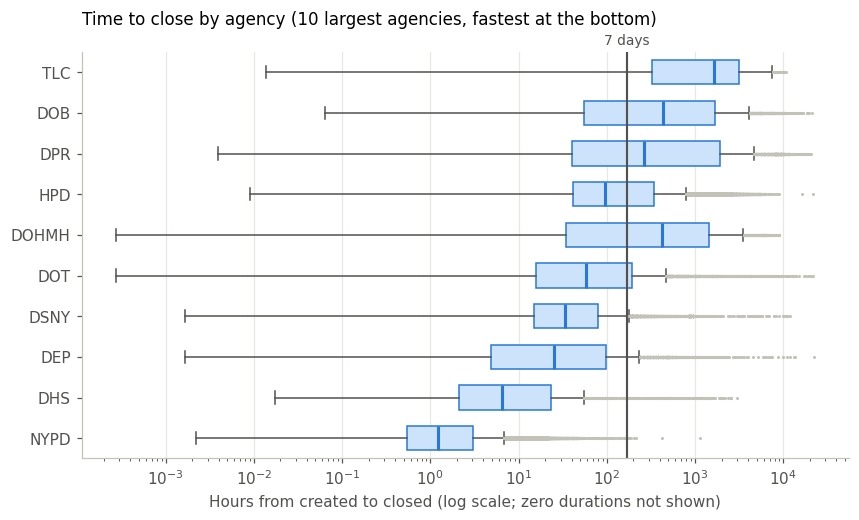

In [29]:
# Boxplot: duration by agency (the 10 agencies with the most requests), log scale
top_agencies = usable["agency"].value_counts().head(10).index.tolist()
order = usable[usable["agency"].isin(top_agencies)].groupby("agency")["duration_hours"].median().sort_values().index
data = [usable.loc[(usable["agency"] == a) & (usable["duration_hours"] > 0), "duration_hours"] for a in order]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.boxplot(data, vert=False, tick_labels=order, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
           whiskerprops=dict(color=INK), capprops=dict(color=INK),
           flierprops=dict(marker=".", markersize=2, markerfacecolor=GREY, markeredgecolor=GREY))
ax.set_xscale("log")
ax.axvline(24 * 7, color=INK, linewidth=1.4)
ax.text(24 * 7, 1.01, "7 days", color=INK, fontsize=9, ha="center", va="bottom", transform=ax.get_xaxis_transform())
ax.set_xlabel("Hours from created to closed (log scale; zero durations not shown)")
ax.set_title("Time to close by agency (10 largest agencies, fastest at the bottom)", loc="left", fontsize=11, pad=18)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_duration_boxplot_by_agency.png")
plt.show()

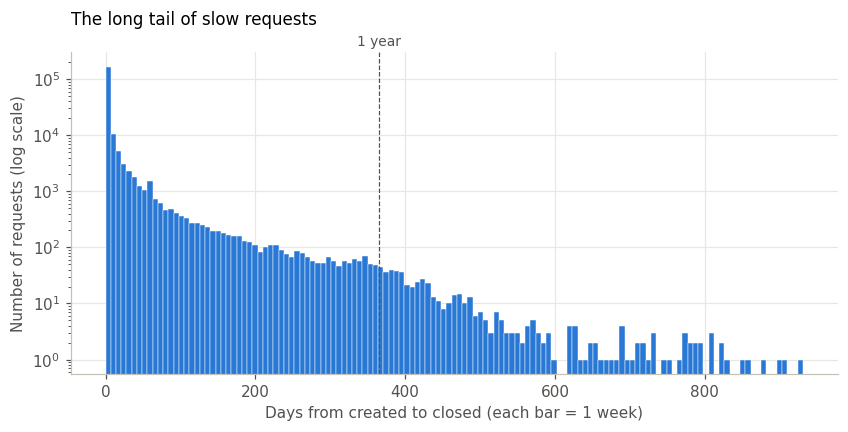

In [30]:
# Histogram: duration in days on a normal (not log) x axis, to show the long tail
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(d / 24, bins=np.arange(0, d.max() / 24 + 7, 7), color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_yscale("log")
ax.axvline(365, color=INK, linewidth=0.8, linestyle="--")
ax.text(365, 1.01, "1 year", color=INK, fontsize=9, ha="center", va="bottom", transform=ax.get_xaxis_transform())
ax.set_xlabel("Days from created to closed (each bar = 1 week)")
ax.set_ylabel("Number of requests (log scale)")
ax.set_title("The long tail of slow requests", loc="left", fontsize=11, pad=18)
fig.savefig(FIG_DIR / "02_duration_histogram_days.png")
plt.show()

**Decision: keep the long durations.** They are real. Some building and tree requests do stay open for months, and the boxplot shows this is normal for certain agencies rather than a few broken rows. They also cannot distort the model, because the model does not predict the number of hours: the target is only "within 7 days, yes or no", so a request that took 20 days and one that took 900 days are both simply class 0. `duration_hours` is kept in the cleaned file for analysis but is never a model input.

### Zero and negative durations

**Check.** A zero duration means `closed_date` equals `created_date` to the second.

In [31]:
zero = usable[usable["duration_hours"] == 0]
print(f"Zero-duration rows: {len(zero):,} ({len(zero) / len(usable):.2%} of usable rows)")

zero_agency = pd.DataFrame({"zero_rows": zero["agency"].value_counts(),
                            "all_rows": usable["agency"].value_counts()}).dropna()
zero_agency["share_of_agency"] = zero_agency["zero_rows"] / zero_agency["all_rows"]
zero_agency = zero_agency.sort_values("zero_rows", ascending=False)
print("\nBy agency")
display(zero_agency.style.format({"zero_rows": "{:,.0f}", "all_rows": "{:,.0f}", "share_of_agency": "{:.1%}"}))

zero_type = pd.DataFrame({"zero_rows": zero["complaint_type"].value_counts(),
                          "all_rows": usable["complaint_type"].value_counts()}).dropna()
zero_type["share_of_type"] = zero_type["zero_rows"] / zero_type["all_rows"]
print("By complaint type (top 10)")
display(zero_type.sort_values("zero_rows", ascending=False).head(10)
        .style.format({"zero_rows": "{:,.0f}", "all_rows": "{:,.0f}", "share_of_type": "{:.1%}"}))

Zero-duration rows: 3,458 (1.74% of usable rows)

By agency


,zero_rows,all_rows,share_of_agency
agency,,,
DOHMH,"1,228","4,538",27.1%
DEP,930,"11,228",8.3%
DOT,702,"12,614",5.6%
DOB,551,"5,694",9.7%
HPD,45,"42,910",0.1%
DSNY,2,"18,404",0.0%


By complaint type (top 10)


,zero_rows,all_rows,share_of_type
complaint_type,,,
Rodent,957,"1,782",53.7%
Water System,894,"4,107",21.8%
Street Condition,486,"4,742",10.2%
General Construction/Plumbing,242,"1,990",12.2%
Traffic Signal Condition,171,"2,718",6.3%
Real Time Enforcement,141,324,43.5%
Unsanitary Animal Pvt Property,82,138,59.4%
Standing Water,56,83,67.5%
Unleashed Dog,52,62,83.9%


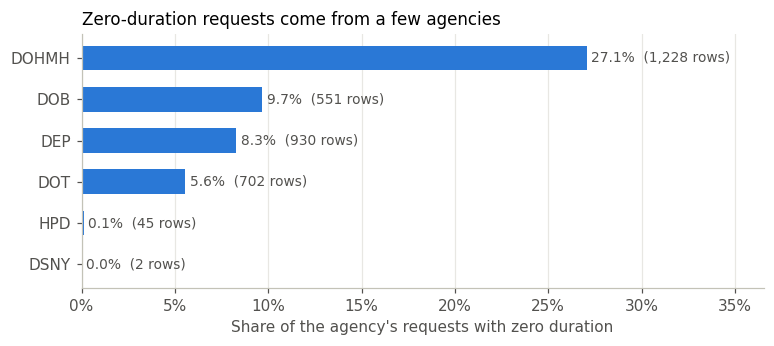

In [32]:
plot = zero_agency["share_of_agency"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}  ({int(n):,} rows)" for v, n in zip(plot.values, zero_agency.loc[plot.index, "zero_rows"])],
             color=INK, fontsize=9, padding=3)
ax.set_xlim(0, plot.max() * 1.35)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Share of the agency's requests with zero duration")
ax.set_title("Zero-duration requests come from a few agencies", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_zero_duration_by_agency.png")
plt.show()

In [33]:
with_duration = pp.add_target(pp.convert_dates(raw))
negative = with_duration[with_duration["duration_hours"] < 0]
print(f"Negative-duration rows: {len(negative)}")
display(negative[["agency", "complaint_type", "created_date", "closed_date", "duration_hours"]]
        .assign(duration_minutes=lambda t: t["duration_hours"] * 60).drop(columns="duration_hours")
        .style.format({"duration_minutes": "{:,.1f}"}))
print("Negative by less than one minute:", int((negative["duration_hours"] > -1 / 60).sum()), "of", len(negative))

Negative-duration rows: 11


,agency,complaint_type,created_date,closed_date,duration_minutes
133376,NYPD,Noise - Residential,2025-11-02 01:34:31,2025-11-02 01:11:16,-23.2
179410,DOT,Street Condition,2026-05-29 16:30:19,2026-05-29 08:57:00,-453.3
193014,DEP,Water Maintenance,2026-07-31 22:48:30,2026-07-31 22:48:00,-0.5
193527,DEP,Water Maintenance,2026-08-03 18:26:27,2026-08-03 18:26:00,-0.4
194376,DEP,Water Maintenance,2026-08-07 14:10:08,2026-08-07 14:10:00,-0.1
195032,DEP,Sewer Maintenance,2026-08-10 19:00:36,2026-08-10 19:00:00,-0.6
195199,DEP,Water Maintenance,2026-08-11 17:40:16,2026-08-11 17:40:00,-0.3
195500,DEP,Sewer Maintenance,2026-08-12 06:21:27,2026-08-12 06:21:00,-0.4
195633,DEP,Water Maintenance,2026-08-13 11:40:26,2026-08-13 11:40:00,-0.4
195869,DEP,Water Maintenance,2026-08-14 08:42:24,2026-08-14 08:42:00,-0.4


Negative by less than one minute: 9 of 11


**Decision: keep the zero-duration rows.** They are not random errors. Almost all of them come from four agencies and a handful of complaint types (rodent reports, water system, street condition, construction), where the agency's system closes the request at the moment it is logged, for example because an inspection is scheduled automatically. A new request of the same kind would be recorded the same way, so this is exactly the pattern the model should learn. Removing them would delete about a quarter of all Health Department requests and bias the data. All of them are class 1 (resolved within 7 days).

*Limitation for the report:* "closed" means the agency closed the request in its system. It does not always mean the problem was physically fixed.

**Decision: drop the negative-duration rows.** A request cannot close before it is created. Most of them are negative by less than a minute, because that agency saves the closing time without seconds, but the rule "duration must be zero or more" is kept simple and they are too few to matter.

**Missing `closed_date`:** these rows have no duration and so no target. They are dropped.

In [34]:
log("Outliers", "Durations longer than 365 days", (d > 365 * 24).sum(),
    "Kept: real slow requests; the target is yes/no, so extreme values cannot distort it")
log("Outliers", "Zero duration (closed_date equals created_date)", len(zero),
    "Kept: a systematic pattern of a few agencies, not random errors")
log("Outliers", "Negative duration (closed before created)", len(negative), "Rows dropped")
log("Outliers", "closed_date missing, so no duration and no target", raw["closed_date"].isna().sum(), "Rows dropped")

### Coordinates outside New York City

**Check.** New York City fits inside latitude 40.47 to 40.93 and longitude -74.27 to -73.68. Anything outside that box (for example 0, 0) would be a wrong location.

Rows with coordinates: 196,284   missing: 3,296
Latitude  range: 40.4990 to 40.9129
Longitude range: -74.2547 to -73.7004
Rows outside the NYC box: 0
Rows with only one of the two coordinates: 0


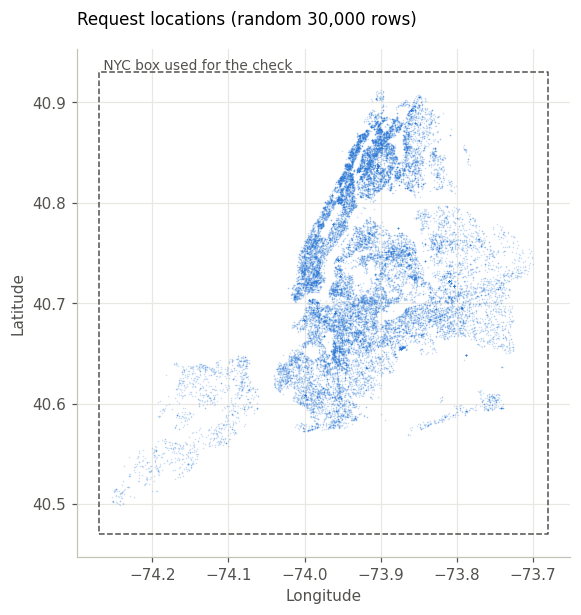

In [35]:
lat = pd.to_numeric(raw["latitude"], errors="coerce")
lon = pd.to_numeric(raw["longitude"], errors="coerce")
outside = lat.notna() & ~(lat.between(*pp.NYC_LAT_RANGE) & lon.between(*pp.NYC_LON_RANGE))
print(f"Rows with coordinates: {lat.notna().sum():,}   missing: {lat.isna().sum():,}")
print(f"Latitude  range: {lat.min():.4f} to {lat.max():.4f}")
print(f"Longitude range: {lon.min():.4f} to {lon.max():.4f}")
print(f"Rows outside the NYC box: {outside.sum():,}")
print(f"Rows with only one of the two coordinates: {(lat.isna() != lon.isna()).sum():,}")

points = pd.DataFrame({"lat": lat, "lon": lon}).dropna().sample(30_000, random_state=42)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(points["lon"], points["lat"], s=1, color=BLUE, alpha=0.25, linewidths=0)
box_lon, box_lat = pp.NYC_LON_RANGE, pp.NYC_LAT_RANGE
ax.plot([box_lon[0], box_lon[1], box_lon[1], box_lon[0], box_lon[0]],
        [box_lat[0], box_lat[0], box_lat[1], box_lat[1], box_lat[0]], color=INK, linewidth=1, linestyle="--")
ax.text(box_lon[0], box_lat[1], " NYC box used for the check", color=INK, fontsize=9, va="bottom")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Request locations (random 30,000 rows)", loc="left", fontsize=11, pad=16)
ax.set_aspect(1.32)     # makes the map look right at New York's latitude
fig.savefig(FIG_DIR / "02_coordinates_map.png")
plt.show()

**Fix.** No coordinate is outside the box, so nothing changes in this dataset. The rule stays in `pp.clean_coordinates` anyway (a point outside the box becomes missing), because the API will receive coordinates typed by users and needs the same protection.

### Unusual `created_date` values

**Check.** Dates outside the requested range, weeks with far too few or too many requests, and timestamps at exactly midnight (often a sign that only the date was recorded).

Earliest: 2024-01-01 00:00:00   latest: 2026-08-31 23:59:06
Outside 2024-01-01 to 2026-08-31: 0
Requests per full week: lowest 1,129, median 1,419, highest 2,200
Days in the range with no requests: 0

Created at exactly 00:00:00: 134 rows (0.07%)
  by agency: {'DOHMH': 111, 'DOT': 21, 'DSNY': 1, 'NYPD': 1}


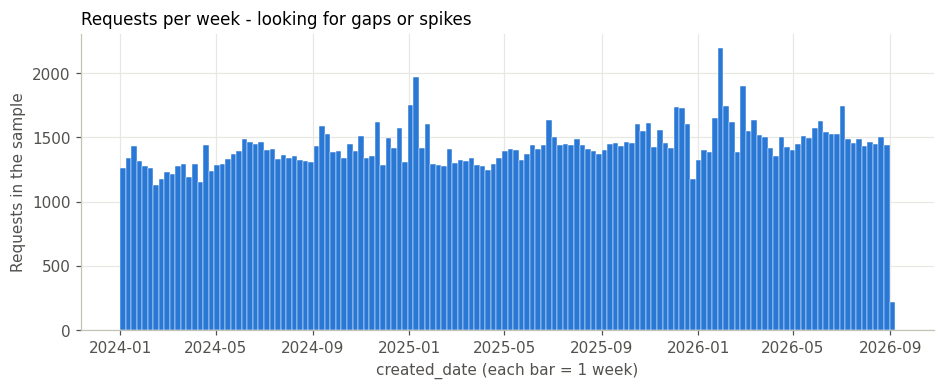

In [36]:
created = dates["created_date"]
print(f"Earliest: {created.min()}   latest: {created.max()}")
print(f"Outside 2024-01-01 to 2026-08-31: {((created < '2024-01-01') | (created >= '2026-09-01')).sum()}")

per_week = created.dt.to_period("W").value_counts().sort_index()
full_weeks = per_week.iloc[1:-1]            # the first and last week are cut by the date range
print(f"Requests per full week: lowest {full_weeks.min():,}, median {full_weeks.median():,.0f}, highest {full_weeks.max():,}")
print(f"Days in the range with no requests: {len(pd.date_range('2024-01-01', '2026-08-31')) - created.dt.date.nunique()}")

midnight = (created.dt.hour == 0) & (created.dt.minute == 0) & (created.dt.second == 0)
print(f"\nCreated at exactly 00:00:00: {midnight.sum():,} rows ({midnight.mean():.2%})")
print("  by agency:", raw.loc[midnight, "agency"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(created, bins=pd.date_range("2024-01-01", "2026-09-07", freq="7D"), color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_xlabel("created_date (each bar = 1 week)")
ax.set_ylabel("Requests in the sample")
ax.set_title("Requests per week - looking for gaps or spikes", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "02_created_per_week.png")
plt.show()

**Decision: nothing to fix.** Every `created_date` is inside the requested range, every day has requests, and there is no gap. The weekly counts move with the seasons, which is expected.

A very small number of rows are stamped exactly 00:00:00, almost all from the Health Department, so their true hour is probably not recorded. They are kept: they are far too few to affect the hour-of-day feature, and there is no way to recover the real time.

In [37]:
log("Outliers", "Coordinates outside the NYC box (lat 40.47-40.93, lon -74.27 to -73.68)", outside.sum(),
    "None found; rule kept in clean_coordinates for API input")
log("Outliers", "created_date outside 2024-01-01 to 2026-08-31", ((created < '2024-01-01') | (created >= '2026-09-01')).sum(),
    "None found")
log("Outliers", "created_date at exactly 00:00:00 (hour probably not recorded)", midnight.sum(),
    "Kept: too few to affect the hour feature")

## 2.6 Values learned from the training period

Some text columns have many values that appear only a handful of times. A model cannot learn anything reliable from a category with 3 examples, and such categories make the model bigger for no gain.

**Rule.** In each text column, a category with fewer than 50 rows **in the training period** is replaced by `"Other"`. The list of categories that are kept is saved to `models/cleaning_values.json`.

**Why training rows only.** If rows from the validation or test period helped decide which categories are "common", information from the future would leak into the model. For the same reason, a category that first appears *after* the training period (or one the API has never seen) becomes `"Other"` too - which is exactly what will happen in real use.

`pp.make_clean_dataset` runs every step of this section in order: convert types, standardize text, add the target, drop unusable rows, sort by date, learn the lists from the training rows, apply them.

In [38]:
clean, values = pp.make_clean_dataset(raw)
clean_train = pp.training_period(clean)
before_other = pp.clean_features(usable)        # same rows, before rare categories are grouped

rows = []
for col in pp.CATEGORICAL_COLUMNS:
    train_values = pp.training_period(before_other)[col]
    rows.append({
        "column": col,
        "categories_in_train": train_values.nunique(),
        "kept": len(values["kept_categories"][col]),
        "become_Other": train_values.nunique() - len(values["kept_categories"][col]),
        "train_rows_Other": int((clean_train[col] == pp.OTHER).sum()),
        "later_rows_Other": int((clean.iloc[len(clean_train):][col] == pp.OTHER).sum()),
        "all_rows_Unknown": int((clean[col] == pp.UNKNOWN).sum()),
    })
learned = pd.DataFrame(rows).set_index("column")
learned["pct_rows_Other"] = (learned["train_rows_Other"] + learned["later_rows_Other"]) / len(clean)
display(learned.style.format("{:,}").format({"pct_rows_Other": "{:.2%}"}))

pp.save_cleaning_values(values, "../models/cleaning_values.json")
print("Saved ../models/cleaning_values.json with:")
print({k: v for k, v in values.items() if k != "kept_categories"})

,categories_in_train,kept,become_Other,train_rows_Other,later_rows_Other,all_rows_Unknown,pct_rows_Other
column,,,,,,,
agency,15,13,2,25,65,0,0.05%
complaint_type,170,102,68,753,779,0,0.77%
descriptor,741,231,510,6887,3632,4453,5.29%
location_type,112,34,78,836,559,24077,0.70%
incident_zip,224,175,49,357,135,1675,0.25%
address_type,7,7,0,0,0,921,0.00%
community_board,72,65,7,119,34,2412,0.08%
borough,6,6,0,0,0,147,0.00%
open_data_channel_type,5,4,1,3,35,15275,0.02%


Saved ../models/cleaning_values.json with:
{'learned_from': 'training period only (oldest 70% of rows by created_date)', 'train_rows': 139206, 'train_start': '2024-01-01 00:00:00', 'train_end': '2025-12-02 20:45:49', 'threshold_days': 7, 'min_category_rows': 50, 'fill_value_missing_text': 'Unknown', 'fill_value_rare_category': 'Other'}


In [39]:
log("Rare categories", "Categories with fewer than 50 rows in the training period (9 text columns)",
    (clean[pp.CATEGORICAL_COLUMNS] == pp.OTHER).any(axis=1).sum(),
    f"Replaced by 'Other' ({learned['become_Other'].sum():,} categories); kept lists saved to models/cleaning_values.json")

## 2.7 Target and leakage columns

`duration_hours` and the target `resolved_within_7d` are added by `pp.add_target`. After that, every column that is only known once a request has been handled is dropped: `closed_date`, `status`, `resolution_description`, `resolution_action_updated_date` and `due_date`.

Only two things derived from them remain in the cleaned file: `duration_hours` (for analysis only) and the target `resolved_within_7d`. Neither is a model input.

In [40]:
print("Columns in the cleaned file:")
print(list(clean.columns))

leaked = set(pp.LEAKAGE_COLUMNS) & set(clean.columns)
assert not leaked, f"leakage columns still present: {leaked}"
print(f"\nLeakage columns present: {sorted(leaked) or 'none'}  (checked: {pp.LEAKAGE_COLUMNS})")

print(f"\nRows: {len(raw):,} raw -> {len(clean):,} clean  ({len(raw) - len(clean):,} dropped)")
print("Target in the cleaned file (all rows):")
print(clean["resolved_within_7d"].value_counts().sort_index().rename({0: "0 = longer than 7 days", 1: "1 = within 7 days"}).to_string())

Columns in the cleaned file:
['unique_key', 'created_date', 'agency', 'complaint_type', 'descriptor', 'location_type', 'incident_zip', 'address_type', 'community_board', 'borough', 'open_data_channel_type', 'latitude', 'longitude', 'duration_hours', 'resolved_within_7d']

Leakage columns present: none  (checked: ['closed_date', 'status', 'resolution_description', 'resolution_action_updated_date', 'due_date'])

Rows: 199,580 raw -> 198,867 clean  (713 dropped)
Target in the cleaned file (all rows):
resolved_within_7d
0 = longer than 7 days     34404
1 = within 7 days         164463


## 2.8 Final checks and saving

A last look at the cleaned table before saving: types, remaining missing values, and no duplicate ids.

In [41]:
summary = pd.DataFrame({"type": clean.dtypes.astype(str), "missing": clean.isna().sum(),
                        "unique_values": clean.nunique()})
display(summary.style.format({"missing": "{:,}", "unique_values": "{:,}"}))

assert clean["unique_key"].is_unique
assert clean["created_date"].is_monotonic_increasing
assert clean[pp.CATEGORICAL_COLUMNS].notna().all().all()          # text columns have no gaps left
assert clean["incident_zip"].str.fullmatch(r"\d{5}|Unknown|Other").all()
assert (clean["duration_hours"] >= 0).all()

Path("../data/processed").mkdir(parents=True, exist_ok=True)
clean.to_parquet("../data/processed/clean.parquet", index=False)
print(f"Saved ../data/processed/clean.parquet: {len(clean):,} rows, {clean.shape[1]} columns")
print(f"created_date from {clean['created_date'].min()} to {clean['created_date'].max()}")

,type,missing,unique_values
unique_key,object,0,"198,867"
created_date,datetime64[ns],0,"197,409"
agency,object,0,14
complaint_type,object,0,103
descriptor,object,0,231
location_type,object,0,34
incident_zip,object,0,176
address_type,object,0,7
community_board,object,0,66
borough,object,0,6


Saved ../data/processed/clean.parquet: 198,867 rows, 15 columns
created_date from 2024-01-01 00:00:00 to 2026-08-31 23:59:06


**Cleaning log.** One row per issue: what was checked, how many rows it touched, and what was done. Saved as `reports/cleaning_log.csv` for the report.

In [42]:
log_table = pd.DataFrame(cleaning_log)
log_table.to_csv("../reports/cleaning_log.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(log_table.style.format({"rows_affected": "{:,}"}).set_properties(**{"text-align": "left"}).hide(axis="index"))
print(f"Saved ../reports/cleaning_log.csv ({len(log_table)} rows)")

issue,check,rows_affected,action
Wrong types,created_date / closed_date stored as text; values that fail to parse,0,Converted to datetime; no parsing failures
Wrong types,latitude / longitude stored as text; values that are not numbers,0,Converted to numbers; no failures
Wrong types,incident_zip not 5 digits or not an NYC ZIP code,36,Kept as 5-digit text; invalid values set to 'Unknown'
Inconsistent data,Text with different case or extra spaces in kept text columns,52,"Trimmed, single-spaced and upper-cased; 6 duplicate spellings merged"
Inconsistent data,"Placeholder values in borough (Unspecified, N/A, UNKNOWN)",147,Mapped to 'Unknown'
Inconsistent data,"Placeholder values in open_data_channel_type (Unspecified, N/A, UNKNOWN)","15,276",Mapped to 'Unknown'
Inconsistent data,"Placeholder values in descriptor (Unspecified, N/A, UNKNOWN)","4,176",Mapped to 'Unknown'
Inconsistent data,"Placeholder values in location_type (Unspecified, N/A, UNKNOWN)",81,Mapped to 'Unknown'
Inconsistent data,"Placeholder values in community_board (Unspecified, N/A, UNKNOWN)","2,617",Mapped to 'Unknown'
Missing values,Columns more than 95% empty (null or placeholder) in the training period,0,"No rows removed. Dropped 10 columns: taxi_company_borough, road_ramp, bridge_highway_direction, facility_type, park_facility_name, due_date, bridge_highway_segment, bridge_highway_name, taxi_pick_up_location, vehicle_type"


Saved ../reports/cleaning_log.csv (30 rows)


# 3. Exploratory charts

These charts describe the cleaned data for the report. All of them use the **training period only**, so nothing we notice here comes from the validation or test rows.

Training period: 139,206 rows, 2024-01-01 00:00:00 to 2025-12-02 20:45:49


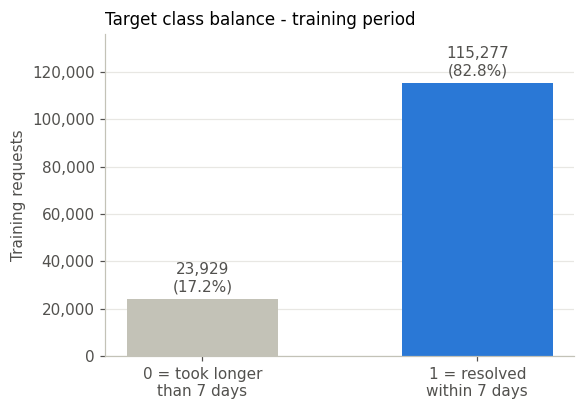

In [43]:
print(f"Training period: {len(clean_train):,} rows, {clean_train['created_date'].min()} to {clean_train['created_date'].max()}")

balance = clean_train["resolved_within_7d"].value_counts().sort_index()
labels = ["0 = took longer\nthan 7 days", "1 = resolved\nwithin 7 days"]
fig, ax = plt.subplots(figsize=(5.5, 3.8))
bars = ax.bar(labels, balance.values, color=[GREY, BLUE], width=0.55)
ax.bar_label(bars, labels=[f"{v:,}\n({v / balance.sum():.1%})" for v in balance.values], color=INK, fontsize=10, padding=3)
ax.set_ylim(0, balance.max() * 1.18)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("Training requests")
ax.set_title("Target class balance - training period", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "03_class_balance.png")
plt.show()

**Reading it.** About 5 in 6 training requests are resolved within 7 days. A model that always answered "within 7 days" would already be right about 83% of the time, so accuracy alone is a weak measure here. Macro F1 and ROC-AUC will be the main metrics.

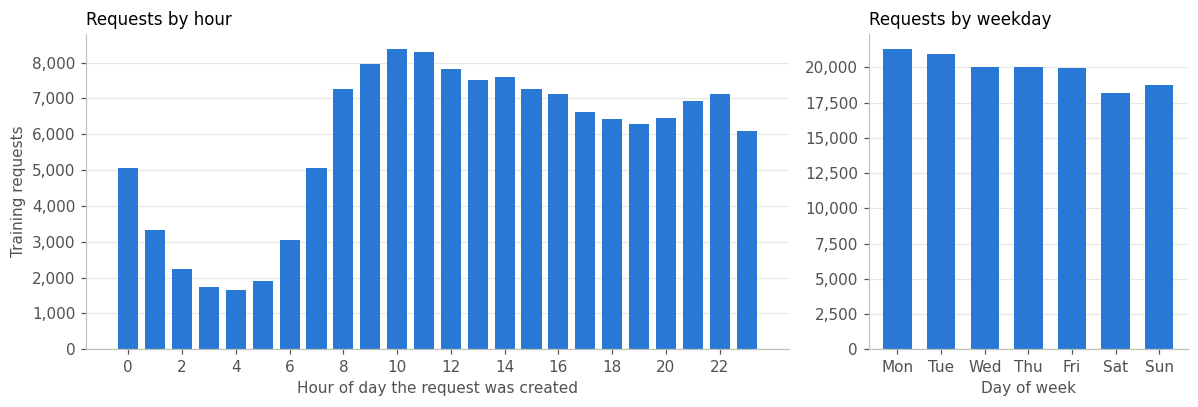

Busiest hour: 10:00 (8,377 requests)   quietest hour: 4:00 (1,652)
Busiest day: Mon (21,296)   quietest day: Sat (18,163)
Share resolved within 7 days, weekday (Mon-Fri) vs weekend: {'weekday': 0.81, 'weekend': 0.879}


In [44]:
hour = clean_train["created_date"].dt.hour.value_counts().sort_index()
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = clean_train["created_date"].dt.dayofweek.value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.bar(hour.index, hour.values, color=BLUE, width=0.75)
ax1.set_xticks(range(0, 24, 2))
ax1.set_xlabel("Hour of day the request was created")
ax1.set_ylabel("Training requests")
ax1.set_title("Requests by hour", loc="left", fontsize=11)
ax2.bar(day_names, weekday.values, color=BLUE, width=0.65)
ax2.set_xlabel("Day of week")
ax2.set_title("Requests by weekday", loc="left", fontsize=11)
for ax in (ax1, ax2):
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_requests_by_hour_weekday.png")
plt.show()

print(f"Busiest hour: {hour.idxmax()}:00 ({hour.max():,} requests)   quietest hour: {hour.idxmin()}:00 ({hour.min():,})")
print(f"Busiest day: {day_names[weekday.idxmax()]} ({weekday.max():,})   quietest day: {day_names[weekday.idxmin()]} ({weekday.min():,})")
print("Share resolved within 7 days, weekday (Mon-Fri) vs weekend:",
      clean_train.groupby(clean_train["created_date"].dt.dayofweek >= 5)["resolved_within_7d"].mean().round(3)
      .rename({False: "weekday", True: "weekend"}).to_dict())

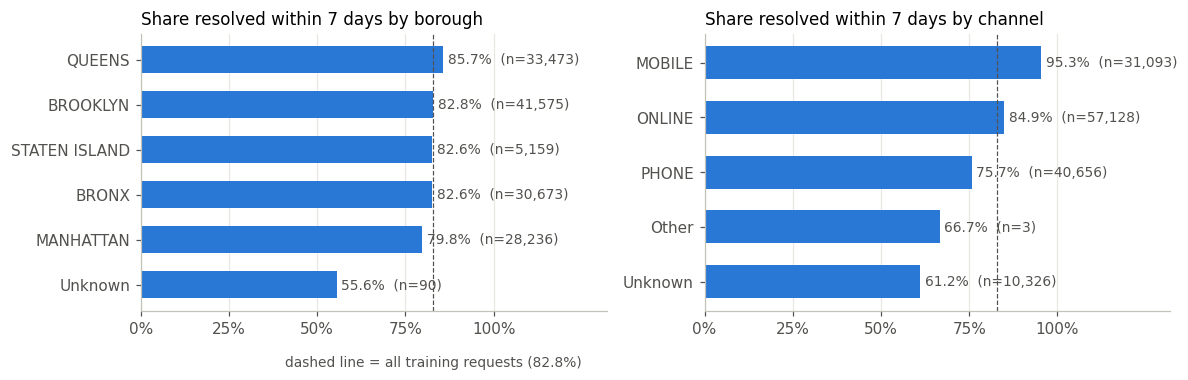

,rows,share_within_7d
borough,,
Unknown,90,55.6%
MANHATTAN,"28,236",79.8%
BRONX,"30,673",82.6%
STATEN ISLAND,"5,159",82.6%
BROOKLYN,"41,575",82.8%
QUEENS,"33,473",85.7%


,rows,share_within_7d
open_data_channel_type,,
Unknown,"10,326",61.2%
Other,3,66.7%
PHONE,"40,656",75.7%
ONLINE,"57,128",84.9%
MOBILE,"31,093",95.3%


In [45]:
def share_table(column):
    t = clean_train.groupby(column)["resolved_within_7d"].agg(rows="size", share_within_7d="mean")
    return t.sort_values("share_within_7d")

by_borough, by_channel = share_table("borough"), share_table("open_data_channel_type")
overall = clean_train["resolved_within_7d"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, table, title in [(axes[0], by_borough, "by borough"), (axes[1], by_channel, "by channel")]:
    bars = ax.barh(table.index, table["share_within_7d"], color=BLUE, height=0.6)
    ax.bar_label(bars, labels=[f"{s:.1%}  (n={n:,})" for s, n in zip(table["share_within_7d"], table["rows"])],
                 color=INK, fontsize=9, padding=3)
    ax.axvline(overall, color=INK, linewidth=0.8, linestyle="--")
    ax.set_xlim(0, 1.32)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(f"Share resolved within 7 days {title}", loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].text(overall, -0.16, f"dashed line = all training requests ({overall:.1%})", color=INK, fontsize=9,
             ha="center", va="top", transform=axes[0].get_xaxis_transform())
fig.tight_layout()
fig.savefig(FIG_DIR / "03_share_by_borough_channel.png")
plt.show()
display(by_borough.style.format({"rows": "{:,}", "share_within_7d": "{:.1%}"}))
display(by_channel.style.format({"rows": "{:,}", "share_within_7d": "{:.1%}"}))

**The 15 most common complaint types** in the training period, with the share resolved within 7 days.

In [46]:
top15 = clean_train.groupby("complaint_type")["resolved_within_7d"].agg(rows="size", share_within_7d="mean")
top15 = top15.sort_values("rows", ascending=False).head(15)
top15.insert(1, "share_of_requests", top15["rows"] / len(clean_train))
display(top15.style.format({"rows": "{:,}", "share_of_requests": "{:.1%}", "share_within_7d": "{:.1%}"}))
print(f"These 15 types cover {top15['rows'].sum() / len(clean_train):.1%} of training requests.")

,rows,share_of_requests,share_within_7d
complaint_type,,,
ILLEGAL PARKING,"21,763",15.6%,100.0%
NOISE - RESIDENTIAL,"16,495",11.8%,100.0%
HEAT/HOT WATER,"10,761",7.7%,99.8%
NOISE - STREET/SIDEWALK,"6,901",5.0%,100.0%
BLOCKED DRIVEWAY,"6,892",5.0%,100.0%
UNSANITARY CONDITION,"4,773",3.4%,39.2%
WATER SYSTEM,"2,848",2.0%,88.4%
ABANDONED VEHICLE,"2,802",2.0%,100.0%
PLUMBING,"2,795",2.0%,46.3%


These 15 types cover 64.9% of training requests.


**What the charts show (training period):**

- **Time of day and week.** Requests follow the working day: few at night (lowest around 4:00), most in the late morning (peak at 10:00), with a second rise in the late evening when noise complaints come in. Weekdays are busier than weekends, but requests filed at the weekend are resolved within 7 days more often (87.9% against 81.0%), because weekend requests are more often noise and parking complaints.
- **Borough.** The boroughs are close together, from 79.8% (Manhattan) to 85.7% (Queens). Borough alone is a weak signal.
- **Channel.** The differences are larger: 95.3% for mobile, 84.9% online, 75.7% by phone and 61.2% when the channel is unknown. Part of this is because different kinds of complaint arrive through different channels.
- **Complaint type.** This is the strongest signal. The 15 most common types cover 64.9% of requests. Police-handled types (illegal parking, noise, blocked driveway, abandoned vehicle) are resolved within 7 days almost every time, while housing types such as unsanitary condition (39.2%), plumbing (46.3%) and paint/plaster (52.0%) are much slower.

**For the next phase.** The cleaned file is `data/processed/clean.parquet`. Phase 4 builds the features (hour, weekday, month, weekend flag), makes the 70 / 15 / 15 split by date, and measures how useful each feature is.